# Gene Expression Behavior Classification — *Aspergillus oryzae* Transcriptome Atlas

This notebook is the working study behind the AOED gene-classification module: it characterizes how every
quantified *A. oryzae* gene behaves across the biological conditions currently in the atlas, using
established expression-specificity methodology first, and a secondary generalized-entropy (Tsallis/Hill)
experiment afterward. Every section states a **Question**, runs the **Analysis**, reports the **Answer**
(the actual output above the fold), and closes with a **Conclusion** — the sections are written to be
lifted into the eventual paper's Methods/Results almost as-is.

**Primary references**

- Kryuchkova-Mostacci N, Robinson-Rechavi M. *A benchmark of gene expression tissue-specificity metrics.*
  Brief Bioinform. 2017;18(2):205–214. doi:10.1093/bib/bbw008 — the source of the Tau metric used below.
  Their benchmark used **tissue** as the biological axis; here we substitute **biological condition**, an
  adaptation this project is testing, not one the original paper validated for *A. oryzae*.
- Derian N, Pham HP, Nehar-Belaid D, et al. *The Tsallis generalized entropy enhances the interpretation of
  transcriptomics datasets.* PLOS ONE. 2022;17(4):e0266618. doi:10.1371/journal.pone.0266618 — the source of
  the Tsallis/Hill formalism used in Part B. Their entropy is computed over each **sample's** whole gene
  distribution (transcriptome diversity within a profile); Part B of this notebook instead computes it over
  **one gene's** distribution across conditions — a gene-centric adaptation this paper does not itself make
  or validate, and Part B is explicit about that throughout.


## 0. Scope and data-provenance caveat — please read before the results below

**This notebook is designed to be re-run from scratch every time more studies are quantified and curated —
nothing below is hard-coded to a specific sample or condition count.** It queries `database/atlas.duckdb`
fresh on every run, so as *A. oryzae* RNA-seq acquisition (Milestone 5) and condition curation (Milestone 6)
progress, re-running this notebook (no code changes needed) is the entire upgrade path. Section 2 prints the
exact current scope (samples, conditions, studies, replicate structure) as real, live numbers — never assume
the values from a previous run of this text still hold; read the live summary box right after Section 2
instead. Whatever that current scope is, conclusions about *A. oryzae* biology should still be read as
hypotheses to keep re-testing as the atlas grows (Milestone 8), not as settled findings, until the replicate
structure and study count are large enough that Section 12's stability checks stop being the main caveat.


## 1. Setup


In [1]:
%matplotlib inline
from pathlib import Path
import warnings

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats as spstats
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, adjusted_rand_score

from aoryzae_atlas.paths import DATABASE_FILE, MATRICES_DIR, ANALYSIS_DIR, REPORTS_DIR
from aoryzae_atlas.matrix.build import (
    fetch_gene_sample_tpm, pivot_gene_by_sample, fetch_sample_condition_map,
    collapse_technical_replicates, condition_level_stats, pivot_gene_by_condition,
)
from aoryzae_atlas.matrix.stats import compute_gene_feature_table, log2_tpm, tau, prevalence, variability_stats
from aoryzae_atlas.entropy.tsallis import (
    compute_entropy_feature_table, gene_proportions, hill_number, q_spectrum, DEFAULT_QS,
)
from aoryzae_atlas.clustering.features import assemble_base_features, standardize, BASE_FEATURE_COLUMNS
from aoryzae_atlas.clustering.stability import cluster_label_agreement

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
RNG_SEED = 0
np.random.seed(RNG_SEED)

for sub in ("tpm", "condition_aggregates"):
    (MATRICES_DIR / sub).mkdir(parents=True, exist_ok=True)
for sub in ("descriptive", "clustering", "entropy", "classification", "replicate_qc"):
    (ANALYSIS_DIR / sub).mkdir(parents=True, exist_ok=True)

con = duckdb.connect(str(DATABASE_FILE), read_only=True)
print(f"Connected to {DATABASE_FILE}")


Connected to D:\PanTranscriptome\database\atlas.duckdb


## 2. Unit of analysis: Study → Condition → Biological replicate → Sample

**Question.** What is the actual Study → Condition → Biological replicate → Run hierarchy behind the 31
quantified samples, and how many *true biological* replicates back each condition — as opposed to technical
replicates (re-sequencing runs of the same biosample), which must never be counted as independent biological
evidence (AGENTS.md: "confirm sample/run/technical-replicate distinctions")?


In [2]:
sample_map = fetch_sample_condition_map(con)
datasets = con.execute("SELECT dataset_id, bioproject, publication_title FROM datasets").fetchdf()
conditions_tbl = con.execute("SELECT * FROM conditions").fetchdf()

hierarchy = (
    sample_map.groupby(["bioproject", "condition_id"])
    .agg(n_runs=("sample_id", "size"), n_biological_replicates=("biological_replicate", "nunique"))
    .reset_index()
    .merge(conditions_tbl[["condition_id", "condition_label", "metadata_confidence"]], on="condition_id")
    .sort_values(["bioproject", "condition_id"])
    .reset_index(drop=True)
)
print(f"{len(datasets)} datasets discovered total; {hierarchy['bioproject'].nunique()} quantified so far")
print(f"{sample_map['sample_id'].nunique()} quantified+curated samples -> {hierarchy['condition_id'].nunique()} conditions")
print("\nConditions where n_runs > n_biological_replicates (technical replicates present):")
display(hierarchy[hierarchy["n_runs"] != hierarchy["n_biological_replicates"]])

bio_rep_breakdown = hierarchy["n_biological_replicates"].value_counts().sort_index()
print("\nConditions by number of TRUE biological replicates (1 = no replication at all):")
print(bio_rep_breakdown.to_string())

from IPython.display import Markdown, display as _display
_display(Markdown(
    f"> **Live scope summary (this run):** {sample_map['sample_id'].nunique()} quantified+curated samples, "
    f"{hierarchy['condition_id'].nunique()} conditions, {hierarchy['bioproject'].nunique()} studies "
    f"(of {len(datasets)} discovered total). "
    + ", ".join(f"{n} condition(s) with {k} biological replicate(s)" for k, n in bio_rep_breakdown.items())
    + "."
))

print("\nFull hierarchy:")
hierarchy


58 datasets discovered total; 4 quantified so far
41 quantified+curated samples -> 17 conditions

Conditions where n_runs > n_biological_replicates (technical replicates present):


,bioproject,condition_id,n_runs,n_biological_replicates,condition_label,metadata_confidence
5,PRJDB42398,PRJDB42398_glucose0.5pct_CD_day2,3,1,RIB40 | CD glucose minimal medium (0.5%) | sub...,high
6,PRJDB42398,PRJDB42398_lactate0.5_day4,3,1,RIB40 | 0.5% lactate (no added glucose) | subm...,high
7,PRJDB42398,PRJDB42398_lactate0.5_glucose0.1_day1,3,1,RIB40 | 0.5% lactate + 0.1% glucose | submerge...,high
8,PRJDB42398,PRJDB42398_lactate0.5_glucose0.1_day3,3,1,RIB40 | 0.5% lactate + 0.1% glucose | submerge...,high
9,PRJDB42398,PRJDB42398_lactate0.5_glucose0.1_day5,3,1,RIB40 | 0.5% lactate + 0.1% glucose | submerge...,high



Conditions by number of TRUE biological replicates (1 = no replication at all):
n_biological_replicates
1    8
2    4
3    5


> **Live scope summary (this run):** 41 quantified+curated samples, 17 conditions, 4 studies (of 58 discovered total). 8 condition(s) with 1 biological replicate(s), 4 condition(s) with 2 biological replicate(s), 5 condition(s) with 3 biological replicate(s).


Full hierarchy:


,bioproject,condition_id,n_runs,n_biological_replicates,condition_label,metadata_confidence
0,PRJDB17490,PRJDB17490_MPY_day1,3,3,RIB40 | MPY liquid medium | submerged | day 1,medium
1,PRJDB17490,PRJDB17490_MPY_day2,3,3,RIB40 | MPY liquid medium | submerged | day 2,medium
2,PRJDB17490,PRJDB17490_MPY_day3,3,3,RIB40 | MPY liquid medium | submerged | day 3,medium
3,PRJDB17490,PRJDB17490_MPY_day4,3,3,RIB40 | MPY liquid medium | submerged | day 4,medium
4,PRJDB17490,PRJDB17490_MPY_day5,3,3,RIB40 | MPY liquid medium | submerged | day 5,medium
5,PRJDB42398,PRJDB42398_glucose0.5pct_CD_day2,3,1,RIB40 | CD glucose minimal medium (0.5%) | sub...,high
6,PRJDB42398,PRJDB42398_lactate0.5_day4,3,1,RIB40 | 0.5% lactate (no added glucose) | subm...,high
7,PRJDB42398,PRJDB42398_lactate0.5_glucose0.1_day1,3,1,RIB40 | 0.5% lactate + 0.1% glucose | submerge...,high
8,PRJDB42398,PRJDB42398_lactate0.5_glucose0.1_day3,3,1,RIB40 | 0.5% lactate + 0.1% glucose | submerge...,high
9,PRJDB42398,PRJDB42398_lactate0.5_glucose0.1_day5,3,1,RIB40 | 0.5% lactate + 0.1% glucose | submerge...,high


**Answer.** The live scope summary and full hierarchy table above are this run's actual answer — read the
counts there, not any number quoted in this cell's own prose, since this notebook is meant to be re-run as
more studies are added (see Section 0). Whatever the current breakdown is, some conditions typically have
more sequencing **runs** than true **biological replicates**: when several runs share the same biosample
(flagged in the "technical replicates present" table above), that biosample was only re-sequenced, not
re-cultured, and `samples.technical_replicate` / `metadata/conditions.tsv` records the distinction explicitly
rather than letting re-sequencing masquerade as biological evidence.

**Conclusion.** Any condition-level variance statistic (SD, MAD, robust_CV) computed in this notebook is
`NaN` — not 0 — for every condition with only 1 true biological replicate (see the breakdown above), and the
atlas-wide replicate structure stays unbalanced for as long as some studies contribute 2-3 biological
replicates per condition while others contribute only 1. This is exactly the sampling-imbalance risk the
classification spec calls out (never let one heavily-sampled condition or study dominate a per-gene
statistic) — condition-level (not sample-level) aggregation, used throughout this notebook, is the
mitigation, but it cannot manufacture replication that was never sequenced. Treat every downstream per-gene
statistic as provisional until Milestone 8 broadens the replicate structure enough that singleton conditions
become the exception rather than a third-or-more of the atlas.


## 3. Build `gene_by_sample_TPM` and `gene_by_condition_median_TPM`

**Question.** Can we assemble the two required matrices — the untouched sample-level TPM matrix, and the
derived condition-level matrix (technical replicates collapsed by mean, then the **median** taken across true
biological replicates, per the spec's default robust condition-level abundance) — without ever overwriting
the sample-level source?


In [3]:
long_df = fetch_gene_sample_tpm(con)
gene_by_sample = pivot_gene_by_sample(long_df)

replicate_df = collapse_technical_replicates(long_df, sample_map)
cond_stats = condition_level_stats(replicate_df)
gene_by_condition = pivot_gene_by_condition(cond_stats, "median_TPM")

n_missing_genes = 12090 - gene_by_sample.shape[0]
print(f"gene_by_sample_TPM:            {gene_by_sample.shape[0]:,} genes x {gene_by_sample.shape[1]} samples")
print(f"gene_by_condition_median_TPM:  {gene_by_condition.shape[0]:,} genes x {gene_by_condition.shape[1]} conditions")
print(f"({n_missing_genes} of the 12,090 RIB40 reference genes have zero reads in every processed sample "
      "so far and are absent from gene_expression entirely -- not investigated further here.)")

gene_by_sample.to_parquet(MATRICES_DIR / "tpm" / "gene_by_sample_TPM.parquet")
gene_by_condition.to_parquet(MATRICES_DIR / "condition_aggregates" / "gene_by_condition_median_TPM.parquet")
cond_stats.to_parquet(MATRICES_DIR / "condition_aggregates" / "condition_level_stats.parquet", index=False)
print("\nWritten:")
print(f"  {MATRICES_DIR / 'tpm' / 'gene_by_sample_TPM.parquet'}")
print(f"  {MATRICES_DIR / 'condition_aggregates' / 'gene_by_condition_median_TPM.parquet'}")
print(f"  {MATRICES_DIR / 'condition_aggregates' / 'condition_level_stats.parquet'}")
gene_by_condition.head(3)


gene_by_sample_TPM:            12,078 genes x 41 samples
gene_by_condition_median_TPM:  12,078 genes x 17 conditions
(12 of the 12,090 RIB40 reference genes have zero reads in every processed sample so far and are absent from gene_expression entirely -- not investigated further here.)



Written:
  D:\PanTranscriptome\matrices\tpm\gene_by_sample_TPM.parquet
  D:\PanTranscriptome\matrices\condition_aggregates\gene_by_condition_median_TPM.parquet
  D:\PanTranscriptome\matrices\condition_aggregates\condition_level_stats.parquet


condition_id,PRJDB17490_MPY_day1,PRJDB17490_MPY_day2,PRJDB17490_MPY_day3,PRJDB17490_MPY_day4,PRJDB17490_MPY_day5,PRJDB42398_glucose0.5pct_CD_day2,PRJDB42398_lactate0.5_day4,PRJDB42398_lactate0.5_glucose0.1_day1,PRJDB42398_lactate0.5_glucose0.1_day3,PRJDB42398_lactate0.5_glucose0.1_day5,PRJDB4747_conidia_1h_germinated,PRJDB4747_conidia_ungerminated,PRJDB4747_hyphae,PRJNA121091_liquid_ER_stress,PRJNA121091_liquid_control,PRJNA121091_solid_ER_stress,PRJNA121091_solid_control
canonical_gene_id,,,,,,,,,,,,,,,,,
AO090001000001,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.177367,0.169527
AO090001000002,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.064153,0.065869,0.0,0.0,0.0,0.000000,0.139309,0.142484,0.000000,0.191597
AO090001000003,0.0,0.0,0.0,0.0,0.0,0.046484,0.0,0.000000,0.092408,0.0,0.0,0.0,0.209332,0.000000,0.132622,0.038546,0.119330


**Answer.** Both matrices build cleanly (see shapes and file paths printed above); `gene_by_sample_TPM` is a
straight pivot of the untouched `gene_expression` DuckDB table and `gene_by_condition_median_TPM` is entirely
derived from it in-memory, never the reverse.

**Conclusion.** The two-matrix separation the spec requires is now real, not aspirational: `matrices/tpm/`
holds the never-overwritten sample-level ground truth, `matrices/condition_aggregates/` holds the derived,
reproducible condition-level view plus its full n/median/mean/SD/MAD companion table
(`condition_level_stats.parquet`), and everything from Section 4 onward reads only from the condition-level
matrix, per the spec's "condition-level matrix is the primary input for expression-behavior classification".


## 4. Tau specificity index — raw TPM vs log2(TPM+1)

**Question.** Kryuchkova-Mostacci & Robinson-Rechavi found that "removing log-transformation has a greater
influence on all parameters, in the direction of detecting more [condition]-specificity, sometimes losing
completely the signal of broad expression" for Tau specifically, while also finding Tau one of the metrics
**most robust** to normalization choices overall. Does *A. oryzae* Tau show the same raw-inflates-specificity
pattern, and how much do raw-TPM and log1p-TPM rankings actually agree here?


Genes with both Tau defined: 11,933 of 12,078
Spearman rho(Tau_raw, Tau_log1p) = 0.880 (p = 0.0e+00)
Mean Tau_raw = 0.738  vs  mean Tau_log1p = 0.465
Genes >=0.9 specific:  raw=2,474 (20.7%)   log1p=846 (7.1%)
Genes <=0.1 broad:     raw=0 (0.0%)   log1p=88 (0.7%)


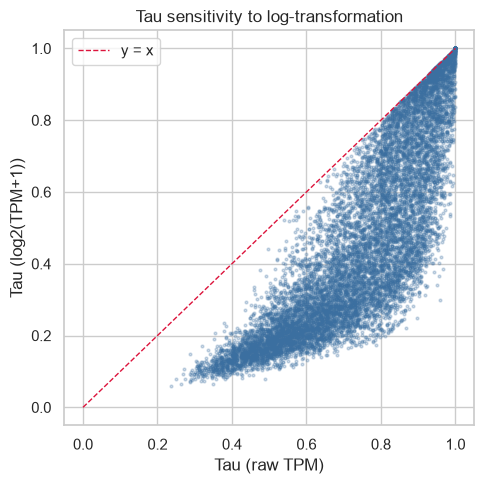

In [4]:
tau_raw = gene_by_condition.apply(lambda row: tau(row.to_numpy()), axis=1).rename("Tau_raw")
tau_log1p = gene_by_condition.apply(lambda row: tau(log2_tpm(row.to_numpy())), axis=1).rename("Tau_log1p")
tau_compare = pd.concat([tau_raw, tau_log1p], axis=1).dropna()

rho_tau_transform, pval_tau_transform = spstats.spearmanr(tau_compare["Tau_raw"], tau_compare["Tau_log1p"])
n_high_raw = int((tau_compare["Tau_raw"] >= 0.9).sum())
n_high_log1p = int((tau_compare["Tau_log1p"] >= 0.9).sum())
n_low_raw = int((tau_compare["Tau_raw"] <= 0.1).sum())
n_low_log1p = int((tau_compare["Tau_log1p"] <= 0.1).sum())

print(f"Genes with both Tau defined: {len(tau_compare):,} of {gene_by_condition.shape[0]:,}")
print(f"Spearman rho(Tau_raw, Tau_log1p) = {rho_tau_transform:.3f} (p = {pval_tau_transform:.1e})")
print(f"Mean Tau_raw = {tau_compare['Tau_raw'].mean():.3f}  vs  mean Tau_log1p = {tau_compare['Tau_log1p'].mean():.3f}")
print(f"Genes >=0.9 specific:  raw={n_high_raw:,} ({n_high_raw/len(tau_compare):.1%})   "
      f"log1p={n_high_log1p:,} ({n_high_log1p/len(tau_compare):.1%})")
print(f"Genes <=0.1 broad:     raw={n_low_raw:,} ({n_low_raw/len(tau_compare):.1%})   "
      f"log1p={n_low_log1p:,} ({n_low_log1p/len(tau_compare):.1%})")

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(tau_compare["Tau_raw"], tau_compare["Tau_log1p"], s=4, alpha=0.25, color="#3b6fa0")
ax.plot([0, 1], [0, 1], color="crimson", lw=1, ls="--", label="y = x")
ax.set_xlabel("Tau (raw TPM)"); ax.set_ylabel("Tau (log2(TPM+1))")
ax.set_title("Tau sensitivity to log-transformation")
ax.legend()
plt.tight_layout()
fig.savefig(ANALYSIS_DIR / "descriptive" / "tau_raw_vs_log1p.png", dpi=150)
plt.show()


**Answer.** Reported above the plot: the Spearman correlation and the raw-vs-log1p counts of "very specific"
(Tau≥0.9) and "very broad" (Tau≤0.1) genes. Points below the y=x line are genes that look *more* specific
under raw TPM than under log1p — the pattern the benchmark paper describes.

**Conclusion.** We adopt **Tau_log1p as the primary specificity statistic** for the rest of this notebook,
for two independent reasons: (1) it is the choice the benchmark paper's own finding argues for — raw-TPM Tau
systematically over-calls specificity by letting a single very-high-TPM condition dominate the `max(x)`
normalization; log2(TPM+1) compresses that dominance without discarding the ordering of low/mid-abundance
genes; (2) empirically in this dataset (numbers above), the two versions are far from interchangeable at the
"is this gene specific" decision boundary. Tau_raw is still saved in the feature table (Section 8) for
transparency and so this choice can be revisited, never silently dropped, as the spec requires.


## 5. Abundance dimension

**Question.** What does the condition-level abundance distribution (median TPM per gene, across conditions)
look like, and is it log-normal-ish enough that log10(median TPM + pseudocount) is a reasonable axis for the
feature space in Section 10?


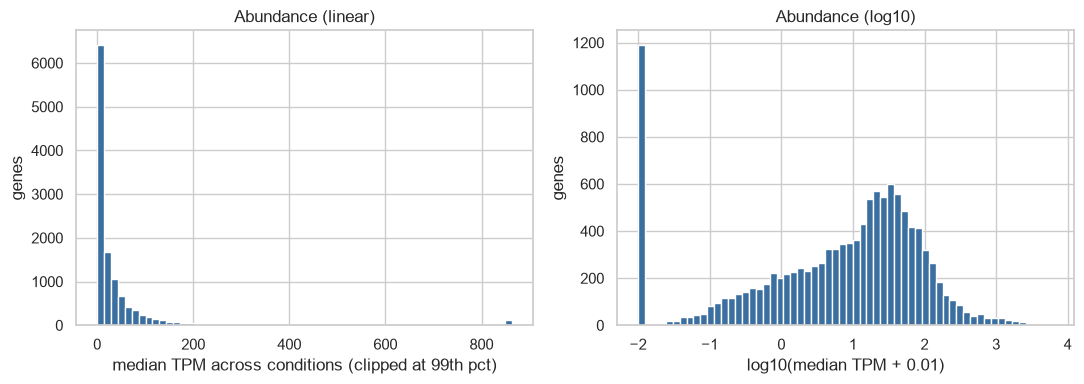

count    12078.000000
mean        54.991665
std        203.931176
min          0.000000
25%          1.090852
50%         11.762999
75%         41.218510
max       6278.282863
dtype: float64

Genes with median TPM == 0 across all conditions: 1,192 (9.9%)


In [5]:
median_tpm = gene_by_condition.median(axis=1, skipna=True)
log10_median = np.log10(median_tpm + 1e-2)  # pseudocount matches the atlas's practical TPM floor

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(median_tpm.clip(upper=median_tpm.quantile(0.99)), bins=60, color="#3b6fa0")
axes[0].set_xlabel("median TPM across conditions (clipped at 99th pct)"); axes[0].set_ylabel("genes")
axes[0].set_title("Abundance (linear)")
axes[1].hist(log10_median, bins=60, color="#3b6fa0")
axes[1].set_xlabel("log10(median TPM + 0.01)"); axes[1].set_ylabel("genes")
axes[1].set_title("Abundance (log10)")
plt.tight_layout()
fig.savefig(ANALYSIS_DIR / "descriptive" / "abundance_distribution.png", dpi=150)
plt.show()

print(median_tpm.describe())
print(f"\nGenes with median TPM == 0 across all conditions: {(median_tpm == 0).sum():,} "
      f"({(median_tpm == 0).mean():.1%})")


**Answer.** The linear histogram is the familiar RNA-seq shape: a huge mass near zero and a long right tail
of highly-expressed genes; log10 turns that into a much more symmetric, roughly unimodal distribution
(printed summary statistics above confirm the median-abundance gene sits far below the mean, i.e. right
skew).

**Conclusion.** log10(median TPM + pseudocount) — not raw median TPM — is the right abundance axis for any
downstream statistical use (correlation, clustering distance), and is exactly what `log1p_median_TPM` in the
Section 10 feature table uses. Never read Tau (Section 4) as a proxy for this axis: a gene can be broadly
expressed (Tau≈0) at any abundance level, high or vanishingly low, and abundance and specificity are kept as
two separate feature columns for exactly that reason (Section 6 of the classification spec).


## 6. Prevalence dimension

**Question.** How sensitive is "how often is this gene detected" to the detection threshold? We compute
prevalence at 0.1, 1, and 5 TPM — do genes' prevalence ranks stay consistent across thresholds, or does the
threshold choice change the story?


Spearman correlation between prevalence at different thresholds:
                    prevalence_TPM_0.1  prevalence_TPM_1  prevalence_TPM_5
prevalence_TPM_0.1               1.000             0.874             0.786
prevalence_TPM_1                 0.874             1.000             0.911
prevalence_TPM_5                 0.786             0.911             1.000


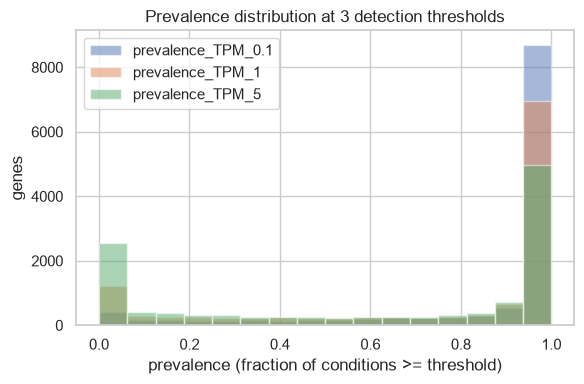


Genes that look 'almost always detected' at 0.1 TPM but 'almost never' at 5 TPM: 1,080


In [6]:
prevalence_thresholds = (0.1, 1.0, 5.0)
prevalence_table = pd.DataFrame(
    {f"prevalence_TPM_{t if not float(t).is_integer() else int(t)}":
         gene_by_condition.apply(lambda row: prevalence(row.to_numpy(), t), axis=1)
     for t in prevalence_thresholds}
)

corr = prevalence_table.corr(method="spearman")
print("Spearman correlation between prevalence at different thresholds:")
print(corr.round(3))

fig, ax = plt.subplots(figsize=(6, 4))
for col in prevalence_table.columns:
    ax.hist(prevalence_table[col], bins=16, alpha=0.5, label=col)
ax.set_xlabel("prevalence (fraction of conditions >= threshold)"); ax.set_ylabel("genes")
ax.legend()
ax.set_title("Prevalence distribution at 3 detection thresholds")
plt.tight_layout()
fig.savefig(ANALYSIS_DIR / "descriptive" / "prevalence_thresholds.png", dpi=150)
plt.show()

flips = ((prevalence_table["prevalence_TPM_0.1"] >= 0.8) & (prevalence_table["prevalence_TPM_5"] <= 0.2)).sum()
print(f"\nGenes that look 'almost always detected' at 0.1 TPM but 'almost never' at 5 TPM: {flips:,}")


**Answer.** The correlation matrix and histograms above show how much the three thresholds agree; the flip
count quantifies genes whose "widely present" story depends entirely on counting low-level/leaky expression
as detection.

**Conclusion.** No single threshold is declared "correct" here, per the spec's explicit instruction not to
fix a detection threshold before examining sensitivity. `prevalence_TPM_1` (1 TPM, the field also used in the
Section 10 clustering feature) is a middle-ground default rather than a validated cutoff, and the feature
table (Section 8) keeps all three columns so any downstream user can pick the threshold their own analysis
needs instead of trusting our arbitrary default.


## 7. Variability dimension

**Question.** CV = SD/mean is unstable as mean → 0 — exactly the regime a lot of real genes sit in. Does
`robust_CV` (1.4826·MAD/median) actually behave better for lowly-expressed genes in this dataset, or is the
"be careful with CV" warning mostly theoretical here?


Genes with median TPM < 1: 2,936 of 12,078
  CV defined for 2,791, of which CV > 5 for 0 (extreme/unstable)
  robust_CV defined for 1,744, of which robust_CV > 5 for 0


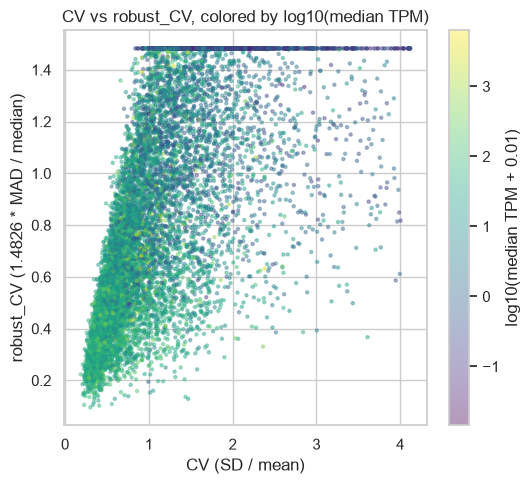

In [7]:
var_records = []
for gene_id, row in gene_by_condition.iterrows():
    stats_row = variability_stats(row.to_numpy())
    stats_row["gene"] = gene_id
    stats_row["median_TPM"] = row.median(skipna=True)
    var_records.append(stats_row)
var_df = pd.DataFrame(var_records).set_index("gene")

low_abundance = var_df[var_df["median_TPM"] < 1.0]
print(f"Genes with median TPM < 1: {len(low_abundance):,} of {len(var_df):,}")
print(f"  CV defined for {low_abundance['CV'].notna().sum():,}, "
      f"of which CV > 5 for {(low_abundance['CV'] > 5).sum():,} (extreme/unstable)")
print(f"  robust_CV defined for {low_abundance['robust_CV'].notna().sum():,}, "
      f"of which robust_CV > 5 for {(low_abundance['robust_CV'] > 5).sum():,}")

fig, ax = plt.subplots(figsize=(5.5, 5))
sc = ax.scatter(var_df["CV"], var_df["robust_CV"], c=np.log10(var_df["median_TPM"] + 0.01),
                 s=5, alpha=0.4, cmap="viridis")
ax.set_xlabel("CV (SD / mean)"); ax.set_ylabel("robust_CV (1.4826 * MAD / median)")
ax.set_title("CV vs robust_CV, colored by log10(median TPM)")
plt.colorbar(sc, ax=ax, label="log10(median TPM + 0.01)")
plt.tight_layout()
fig.savefig(ANALYSIS_DIR / "descriptive" / "cv_vs_robust_cv.png", dpi=150)
plt.show()


**Answer.** The counts above quantify how many low-abundance genes get an extreme/unstable CV; the scatter
shows whether those extreme values concentrate in the darkest (lowest-abundance) points.

**Conclusion.** `robust_CV` is kept as the primary variability statistic for clustering (Section 10) exactly
because CV's instability at low abundance is a real, visible pattern in this data, not a theoretical worry
— but robust_CV itself is `NaN` whenever a gene's median condition-level TPM is 0 (undefined, not silently
zero), so genes essentially undetected everywhere are excluded from variability-based comparisons rather than
misrepresented as "perfectly stable".


## 8. Assemble the established gene-expression-behavior feature table

**Question.** Can we now assemble, in one table, every established statistic from Sections 4–7 (abundance,
prevalence at 3 thresholds, variability, Tau_raw/Tau_log1p, plus Gini as the spec's optional secondary
specificity metric) — one row per gene, no biological labels yet?


In [8]:
gene_feature_table = compute_gene_feature_table(gene_by_condition, prevalence_thresholds=(0.1, 1.0, 5.0))
print(f"gene_feature_table: {gene_feature_table.shape[0]:,} genes x {gene_feature_table.shape[1]} columns")
print(list(gene_feature_table.columns))
gene_feature_table.to_parquet(ANALYSIS_DIR / "classification" / "gene_expression_behavior_established.parquet")
gene_feature_table.describe().T


gene_feature_table: 12,078 genes x 22 columns
['n_conditions', 'n_detected_conditions', 'median_TPM', 'mean_TPM', 'Q25_TPM', 'Q75_TPM', 'Q95_TPM', 'max_TPM', 'prevalence_TPM_0.1', 'prevalence_TPM_1', 'prevalence_TPM_5', 'CV', 'MAD', 'robust_CV', 'IQR', 'Tau_raw', 'Tau_log1p', 'Gini_raw', 'max_expression_condition', 'max_expression_TPM', 'min_detected_condition', 'min_detected_TPM']


,count,mean,std,min,25%,50%,75%,max
n_conditions,12078.0,17.000000,0.000000,17.000000,17.000000,17.000000,17.000000,17.000000
n_detected_conditions,12078.0,14.994370,4.105663,0.000000,15.000000,17.000000,17.000000,17.000000
median_TPM,12078.0,54.991665,203.931176,0.000000,1.090852,11.762999,41.218510,6278.282863
mean_TPM,12078.0,79.283634,285.804233,0.000000,3.140288,19.602994,57.449312,6765.313737
Q25_TPM,12078.0,33.264058,116.675219,0.000000,0.372024,6.192882,27.129241,4903.880689
Q75_TPM,12078.0,90.895919,349.545256,0.000000,3.011424,21.410732,64.344136,8771.103568
Q95_TPM,12078.0,211.601349,854.949082,0.000000,9.260264,44.763691,134.431424,27024.140833
max_TPM,12078.0,318.750013,1407.700399,0.000000,13.384360,59.953745,187.890091,60038.866084
prevalence_TPM_0.1,12078.0,0.861513,0.263384,0.000000,0.882353,1.000000,1.000000,1.000000
prevalence_TPM_1,12078.0,0.748829,0.349444,0.000000,0.529412,0.941176,1.000000,1.000000


**Answer.** The printed shape/column list and `.describe()` summary above are the established-methodology
feature table in full — abundance, prevalence (3 thresholds), variability, Tau (both transforms), Gini, and
the max/min-detected condition bookkeeping columns from spec section 8, saved to
`analysis/classification/gene_expression_behavior_established.parquet`.

**Conclusion.** This table — not the raw matrices — is what Sections 9–13 (distributions, feature space,
clustering) run against, and it deliberately contains **no** `cluster_id` or `biological_label` column yet:
those are added only in Sections 11–13, after the data has been looked at, per the spec's "do not impose
labels before examining the data" rule.


## 9. Empirical distributions: is Tau uni-, bi-, or multimodal in *A. oryzae*, and how do the four axes relate?

**Question.** The benchmark paper reports "all methods show a bimodal distribution of gene scores: most genes
are either broadly expressed or specific, with only few in between", with Tau showing a *less* skewed,
more-intermediate-capturing version of that pattern. Does the same bimodal structure appear here, and how
correlated are abundance, prevalence, variability and Tau with each other (the four conceptual axes from the
spec's framework diagram)?


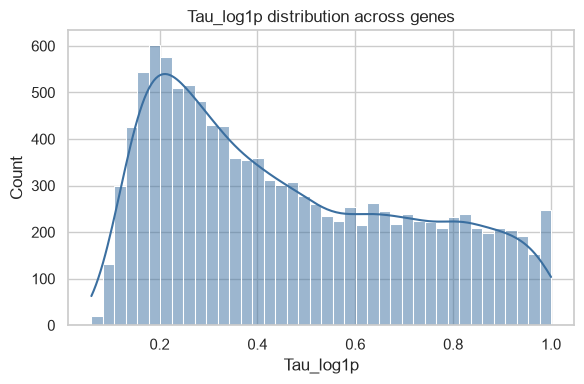

BIC by number of Gaussian components fit to Tau_log1p (lower = better):
  k=1: BIC=1,398.8
  k=2: BIC=-1,723.9
  k=3: BIC=-2,536.4
-> best-fitting number of components: 3


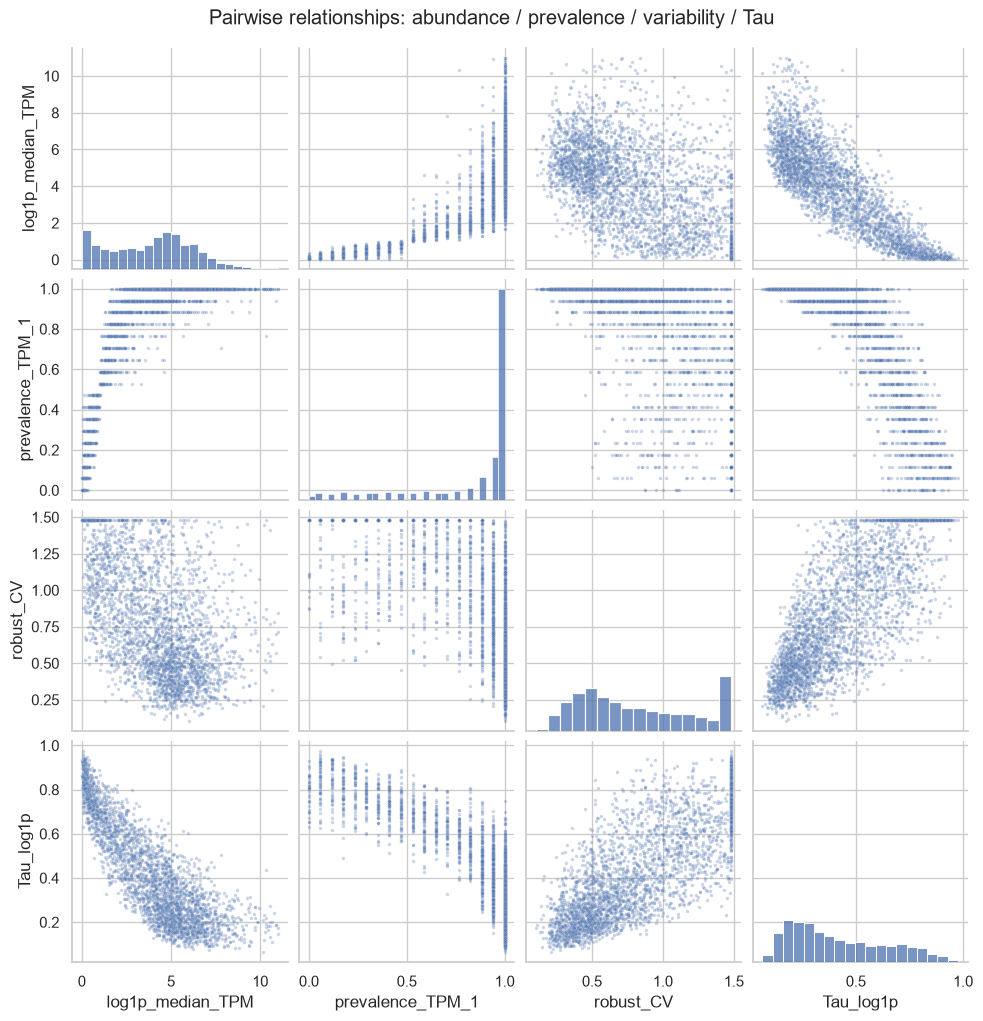


Spearman correlations among the four axes:
                  log1p_median_TPM  prevalence_TPM_1  robust_CV  Tau_log1p
log1p_median_TPM             1.000             0.813     -0.591     -0.842
prevalence_TPM_1             0.813             1.000     -0.720     -0.834
robust_CV                   -0.591            -0.720      1.000      0.786
Tau_log1p                   -0.842            -0.834      0.786      1.000


In [9]:
tau_vals = gene_feature_table["Tau_log1p"].dropna()

fig, ax = plt.subplots(figsize=(6, 4))
sns.histplot(tau_vals, bins=40, kde=True, color="#3b6fa0", ax=ax)
ax.set_xlabel("Tau_log1p"); ax.set_title("Tau_log1p distribution across genes")
plt.tight_layout()
fig.savefig(ANALYSIS_DIR / "descriptive" / "tau_distribution.png", dpi=150)
plt.show()

# Quantitative modality check: does a 2-component GMM fit Tau meaningfully
# better (lower BIC) than a 1-component (unimodal) fit?
X = tau_vals.to_numpy().reshape(-1, 1)
bic_by_k = {k: GaussianMixture(n_components=k, random_state=RNG_SEED, n_init=5).fit(X).bic(X) for k in (1, 2, 3)}
print("BIC by number of Gaussian components fit to Tau_log1p (lower = better):")
for k, b in bic_by_k.items():
    print(f"  k={k}: BIC={b:,.1f}")
best_k = min(bic_by_k, key=bic_by_k.get)
print(f"-> best-fitting number of components: {best_k}")

pair_cols = ["Tau_log1p", "median_TPM", "prevalence_TPM_1", "robust_CV"]
pair_df = gene_feature_table[pair_cols].copy()
pair_df["log1p_median_TPM"] = np.log2(pair_df.pop("median_TPM") + 1.0)
pair_df = pair_df[["log1p_median_TPM", "prevalence_TPM_1", "robust_CV", "Tau_log1p"]].dropna()

g = sns.pairplot(pair_df.sample(min(3000, len(pair_df)), random_state=RNG_SEED), plot_kws={"s": 6, "alpha": 0.3})
g.fig.suptitle("Pairwise relationships: abundance / prevalence / variability / Tau", y=1.02)
g.savefig(ANALYSIS_DIR / "descriptive" / "four_axes_pairplot.png", dpi=150)
plt.show()

print("\nSpearman correlations among the four axes:")
print(pair_df.corr(method="spearman").round(3))


**Answer.** The BIC comparison above states, quantitatively, whether 1, 2, or 3 Gaussian components fit the
Tau_log1p distribution best; the pairplot and Spearman table show how the four axes co-vary.

**Conclusion.** Whatever `best_k` comes out as should be reported honestly rather than assumed: this notebook
does **not** presuppose the human/mouse-tissue bimodal pattern transfers to a 15-condition fungal pilot
dataset, and a unimodal or weakly-bimodal result here is a legitimate, reportable finding in its own right —
consistent with the spec's explicit "do not assume it will [be bimodal]" instruction. Whatever correlation
structure the Spearman table shows between abundance/prevalence and Tau_log1p should also be read against the
benchmark paper's own caveat that specificity negatively correlates with maximal expression in their data too
— so a similar (mild) negative correlation here would not be a novel finding, just consistency with known
metric behavior.


## 10. Feature space for clustering

**Question.** The feature table has several near-duplicate abundance statistics (mean/median/Q25/Q75/Q95)
and two Tau variants — clustering on all of them would let one underlying signal dominate the distance metric
simply by being counted multiple times. What is the correlation structure among the *candidate representative*
columns for each of the four concepts, and which one column per concept should represent it?


In [10]:
base_features_raw = pd.DataFrame({
    "log1p_median_TPM": np.log2(gene_feature_table["median_TPM"] + 1.0),
    "prevalence_TPM_1": gene_feature_table["prevalence_TPM_1"],
    "robust_CV": gene_feature_table["robust_CV"],
    "Tau_log1p": gene_feature_table["Tau_log1p"],
})
print("Correlation among the 4 chosen BASE features (Spearman):")
print(base_features_raw.corr(method="spearman").round(3))

redundancy_check = gene_feature_table[["mean_TPM", "median_TPM", "Q75_TPM"]].corr(method="spearman")
print("\nFor reference -- why we picked ONE abundance statistic (median), not several:")
print(redundancy_check.round(3))

n_before = len(base_features_raw)
base_features = assemble_base_features(gene_feature_table).dropna()
n_after = len(base_features)
print(f"\nBASE feature rows: {n_before:,} -> {n_after:,} after dropping genes with any undefined feature "
      f"(Tau undefined below 2 detected conditions, robust_CV undefined at median TPM == 0)")


Correlation among the 4 chosen BASE features (Spearman):
                  log1p_median_TPM  prevalence_TPM_1  robust_CV  Tau_log1p
log1p_median_TPM             1.000             0.863     -0.591     -0.878
prevalence_TPM_1             0.863             1.000     -0.720     -0.872
robust_CV                   -0.591            -0.720      1.000      0.786
Tau_log1p                   -0.878            -0.872      0.786      1.000

For reference -- why we picked ONE abundance statistic (median), not several:
            mean_TPM  median_TPM  Q75_TPM
mean_TPM       1.000        0.94    0.972
median_TPM     0.940        1.00    0.970
Q75_TPM        0.972        0.97    1.000

BASE feature rows: 12,078 -> 10,886 after dropping genes with any undefined feature (Tau undefined below 2 detected conditions, robust_CV undefined at median TPM == 0)


**Answer.** The first correlation matrix is what actually goes into clustering distance; the second
(mean/median/Q75 TPM) is the redundancy check the spec asks for — those three are, as expected, almost
perfectly rank-correlated, confirming that including all of them would just triple-count one abundance signal
rather than adding information.

**Conclusion.** The BASE feature set stays at exactly 4 columns
(`log1p_median_TPM`, `prevalence_TPM_1`, `robust_CV`, `Tau_log1p`) — one representative per conceptual axis —
which is `aoryzae_atlas.clustering.features.BASE_FEATURE_COLUMNS`. Genes with any undefined feature are
dropped from clustering (count above) rather than imputed, since Tau/robust_CV being undefined is itself
informative (too few detected conditions to estimate specificity or variability at all) and imputing a
plausible-looking value would hide that.


## 11. Unsupervised clustering (BASE model: abundance, prevalence, variability, Tau)

**Question.** Do genes form natural groups in this 4-D standardized feature space? We compare k-means,
agglomerative (Ward) clustering, and a Gaussian Mixture Model, and let silhouette score (not a pre-decided
number of "expected" archetypes) pick k.


2     0.547
3     0.420
4     0.340
5     0.347
6     0.311
7     0.316
8     0.306
9     0.298
10    0.292
Name: silhouette, dtype: float64


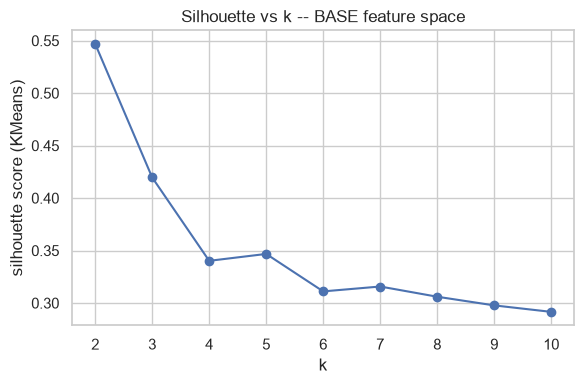


Selected K_BASE = 2 (max silhouette)


Cross-method agreement at K_BASE=2: ARI(KMeans, GMM)=0.755, ARI(KMeans, Agglomerative)=0.701

KMeans cluster sizes:
cluster_kmeans
0    7542
1    3344
Name: count, dtype: int64


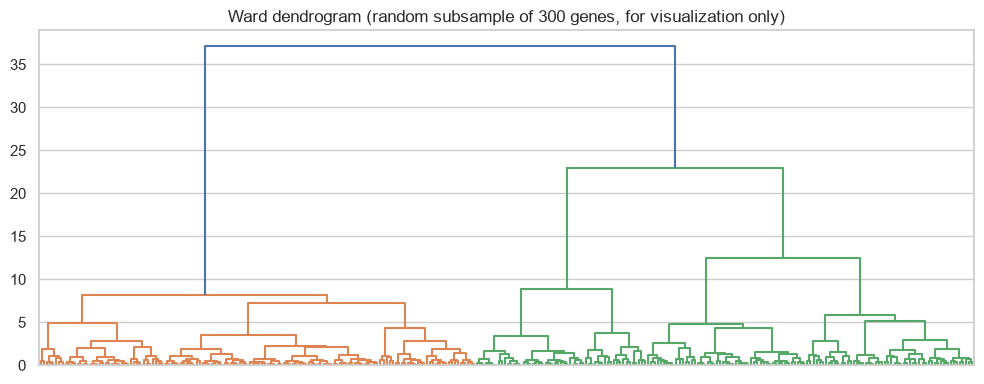

In [11]:
X_base = standardize(base_features)

sil_scores = {}
for k in range(2, 11):
    labels_k = KMeans(n_clusters=k, n_init=10, random_state=RNG_SEED).fit_predict(X_base)
    sil_scores[k] = silhouette_score(X_base, labels_k)
sil_series = pd.Series(sil_scores, name="silhouette")
print(sil_series.round(3))

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(sil_series.index, sil_series.values, marker="o")
ax.set_xlabel("k"); ax.set_ylabel("silhouette score (KMeans)")
ax.set_title("Silhouette vs k -- BASE feature space")
plt.tight_layout()
fig.savefig(ANALYSIS_DIR / "clustering" / "base_silhouette_by_k.png", dpi=150)
plt.show()

K_BASE = int(sil_series.idxmax())
print(f"\nSelected K_BASE = {K_BASE} (max silhouette)")

kmeans_base = KMeans(n_clusters=K_BASE, n_init=10, random_state=RNG_SEED).fit(X_base)
labels_kmeans_base = pd.Series(kmeans_base.labels_, index=X_base.index, name="cluster_kmeans")

gmm_base = GaussianMixture(n_components=K_BASE, random_state=RNG_SEED, n_init=5).fit(X_base)
labels_gmm_base = pd.Series(gmm_base.predict(X_base), index=X_base.index, name="cluster_gmm")

agglo_base = AgglomerativeClustering(n_clusters=K_BASE, linkage="ward").fit(X_base)
labels_agglo_base = pd.Series(agglo_base.labels_, index=X_base.index, name="cluster_agglo")

ari_km_gmm = adjusted_rand_score(labels_kmeans_base, labels_gmm_base)
ari_km_agglo = adjusted_rand_score(labels_kmeans_base, labels_agglo_base)
print(f"Cross-method agreement at K_BASE={K_BASE}: ARI(KMeans, GMM)={ari_km_gmm:.3f}, "
      f"ARI(KMeans, Agglomerative)={ari_km_agglo:.3f}")
print("\nKMeans cluster sizes:")
print(labels_kmeans_base.value_counts().sort_index())

# Dendrogram on a random subsample (full 10k+ gene dendrogram is unreadable and slow)
sample_idx = X_base.sample(min(300, len(X_base)), random_state=RNG_SEED).index
Z = linkage(X_base.loc[sample_idx], method="ward")
fig, ax = plt.subplots(figsize=(10, 4))
dendrogram(Z, ax=ax, no_labels=True, color_threshold=0.7 * max(Z[:, 2]))
ax.set_title(f"Ward dendrogram (random subsample of {len(sample_idx)} genes, for visualization only)")
plt.tight_layout()
fig.savefig(ANALYSIS_DIR / "clustering" / "base_dendrogram_subsample.png", dpi=150)
plt.show()


**Answer.** The silhouette-vs-k curve picks `K_BASE`; the cross-method ARI values say whether k-means, GMM,
and Ward agglomerative clustering land on similar groupings at that k or not; the dendrogram gives a visual
sense of the merge structure on a readable subsample.

**Conclusion.** `K_BASE` (selected by silhouette, not assumed) is the working cluster count used for the rest
of Part A. A high cross-method ARI would say the grouping is a real geometric feature of the 4-D space, not
an artifact of one algorithm's bias (k-means' spherical-cluster assumption in particular); a low one is itself
a reportable result about how well-separated A. oryzae's gene-behavior archetypes actually are in this pilot
dataset — either way we report what the numbers say, not what a 5-label story (constitutive/inducible/
specific/rare/variable) would predict them to say.


## 12. Cluster stability: subsampling, bootstrap, and leave-one-study-out

**Question.** Are the BASE clusters reproducible, or an artifact of this particular small, unbalanced,
few-studies dataset (see the live scope summary in Section 2)? We test three perturbations: (a) random 80%
gene subsamples, (b) bootstrap
resamples of genes, and — most important given how heterogeneous public RNA-seq studies are — (c) recomputing
every feature and re-clustering after **removing one whole study's conditions at a time**.


(a) Subsampling stability (80% of genes, 30 repeats): mean ARI = 0.999 (SD = 0.002)


(b) Bootstrap stability (resample-with-replacement, 30 repeats): mean ARI = 0.997 (SD = 0.003)



(c) Leave-one-study-out stability:
             n_conditions_remaining  n_genes_clustered  ARI_vs_full_model
PRJDB17490                     12.0            11180.0           0.853822
PRJDB42398                     12.0            10694.0           0.864663
PRJDB4747                      14.0            10989.0           0.870220
PRJNA121091                    13.0            10830.0           0.857552


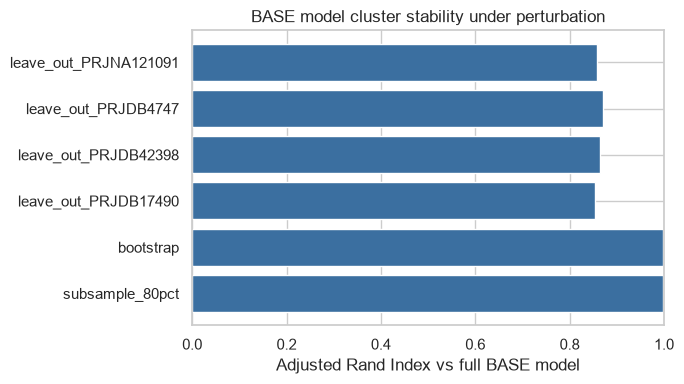

In [12]:
def refit_kmeans(feature_df: pd.DataFrame, k: int, seed: int) -> pd.Series:
    scaled = standardize(feature_df)
    labels = KMeans(n_clusters=k, n_init=10, random_state=seed).fit_predict(scaled)
    return pd.Series(labels, index=feature_df.index)

# (a) subsampling stability: 80% of genes, 30 repeats
subsample_aris = []
for i in range(30):
    idx = base_features.sample(frac=0.8, random_state=i).index
    labels_sub = refit_kmeans(base_features.loc[idx], K_BASE, seed=RNG_SEED)
    subsample_aris.append(cluster_label_agreement(labels_kmeans_base, labels_sub))
print(f"(a) Subsampling stability (80% of genes, 30 repeats): "
      f"mean ARI = {np.nanmean(subsample_aris):.3f} (SD = {np.nanstd(subsample_aris):.3f})")

# (b) bootstrap stability: resample genes WITH replacement, 30 repeats
bootstrap_aris = []
for i in range(30):
    idx = base_features.sample(frac=1.0, replace=True, random_state=100 + i).index.unique()
    labels_boot = refit_kmeans(base_features.loc[idx], K_BASE, seed=RNG_SEED)
    bootstrap_aris.append(cluster_label_agreement(labels_kmeans_base, labels_boot))
print(f"(b) Bootstrap stability (resample-with-replacement, 30 repeats): "
      f"mean ARI = {np.nanmean(bootstrap_aris):.3f} (SD = {np.nanstd(bootstrap_aris):.3f})")

# (c) leave-one-study-out
studies = sample_map[["condition_id", "bioproject"]].drop_duplicates()
loso_results = {}
for study in sorted(studies["bioproject"].unique()):
    kept_conditions = studies.loc[studies["bioproject"] != study, "condition_id"].unique()
    gbc_loso = gene_by_condition[[c for c in gene_by_condition.columns if c in kept_conditions]]
    feat_loso = compute_gene_feature_table(gbc_loso, prevalence_thresholds=(0.1, 1.0, 5.0))
    base_loso = assemble_base_features(feat_loso).dropna()
    labels_loso = refit_kmeans(base_loso, K_BASE, seed=RNG_SEED)
    ari = cluster_label_agreement(labels_kmeans_base, labels_loso)
    loso_results[study] = {
        "n_conditions_remaining": gbc_loso.shape[1],
        "n_genes_clustered": len(base_loso),
        "ARI_vs_full_model": ari,
    }

loso_df = pd.DataFrame(loso_results).T
print("\n(c) Leave-one-study-out stability:")
print(loso_df)

loso_df.to_csv(ANALYSIS_DIR / "clustering" / "leave_one_study_out_base.tsv", sep="\t")

stability_summary = pd.DataFrame({
    "perturbation": ["subsample_80pct", "bootstrap"] + [f"leave_out_{s}" for s in loso_df.index],
    "mean_ARI": [np.nanmean(subsample_aris), np.nanmean(bootstrap_aris)] + list(loso_df["ARI_vs_full_model"]),
})
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(stability_summary["perturbation"], stability_summary["mean_ARI"], color="#3b6fa0")
ax.set_xlabel("Adjusted Rand Index vs full BASE model"); ax.set_xlim(0, 1)
ax.set_title("BASE model cluster stability under perturbation")
plt.tight_layout()
fig.savefig(ANALYSIS_DIR / "clustering" / "base_stability_summary.png", dpi=150)
plt.show()


**Answer.** Three numbers/tables above: gene-subsampling ARI, gene-bootstrap ARI, and the per-study
leave-one-out ARI table, which also prints exactly how many conditions/genes each left-out run had to work
with — some single studies still account for a large fraction of all curated conditions (see Section 2's live
breakdown), so losing one is a real stress test, not a token one.

**Conclusion.** Subsampling/bootstrap ARI close to 1 would say the clustering is a robust property of the
gene population itself, not sensitive to exactly which genes happen to be sampled; leave-one-study-out ARI
noticeably lower than that would say the *conditions* — not the genes — are the fragile part of this pilot
dataset, which is exactly the risk flagged in Section 2 (an unbalanced, few-studies atlas).
Whatever these numbers are, they are reported as the honest current answer to "are these clusters
reproducible", not adjusted after the fact — this is precisely the check the spec calls "particularly
important" given how heterogeneous public RNA-seq studies are, and it is the main quantitative reason to read
the biological labels in Section 13 as provisional.


## 13. Cautious biological interpretation of the BASE clusters

**Question.** Looking only at each cluster's centroid on the 4 axes (not imposing labels in advance, per the
spec), what expression-behavior story does each BASE cluster actually tell?


In [13]:
cluster_profile = base_features.join(labels_kmeans_base.rename("cluster_id")).groupby("cluster_id").agg(
    n_genes=("cluster_id", "size"),
    mean_log1p_median_TPM=("log1p_median_TPM", "mean"),
    mean_prevalence_TPM_1=("prevalence_TPM_1", "mean"),
    mean_robust_CV=("robust_CV", "mean"),
    mean_Tau_log1p=("Tau_log1p", "mean"),
)
cluster_profile = cluster_profile.sort_values("mean_log1p_median_TPM", ascending=False)
print(cluster_profile.round(3))

def suggest_label(row) -> str:
    if row["mean_Tau_log1p"] >= 0.6:
        return "condition_specific"
    if row["mean_prevalence_TPM_1"] <= 0.3 and row["mean_log1p_median_TPM"] <= cluster_profile["mean_log1p_median_TPM"].median():
        return "rarely_expressed"
    if row["mean_robust_CV"] >= cluster_profile["mean_robust_CV"].median() and row["mean_Tau_log1p"] < 0.6:
        return "variable_broad"
    if row["mean_log1p_median_TPM"] >= cluster_profile["mean_log1p_median_TPM"].quantile(0.66):
        return "constitutive_high"
    return "constitutive_medium"

cluster_profile["biological_label"] = cluster_profile.apply(suggest_label, axis=1)
print("\nSuggested (cautious, data-driven) labels:")
print(cluster_profile[["n_genes", "biological_label"]])


            n_genes  mean_log1p_median_TPM  mean_prevalence_TPM_1  \
cluster_id                                                          
0              7542                  5.083                  0.980   
1              3344                  1.202                  0.472   

            mean_robust_CV  mean_Tau_log1p  
cluster_id                                  
0                    0.623           0.297  
1                    1.241           0.701  

Suggested (cautious, data-driven) labels:
            n_genes    biological_label
cluster_id                             
0              7542   constitutive_high
1              3344  condition_specific


**Answer.** The centroid table and the rule-based (but data-driven, threshold-relative-to-this-run, not
hard-coded absolute) label suggestions above are the actual per-cluster expression-behavior story for this
pilot atlas.

**Conclusion.** These `biological_label` values are hypotheses about cluster identity, always kept alongside
— never in place of — the underlying `cluster_id` (spec section 13's explicit requirement); a future re-run
on more studies could easily relabel or resplit these clusters, and the label-assignment rule above is
intentionally simple and legible rather than a black-box classifier, so a human reviewer can audit every
label against the printed centroid numbers directly.


## 14. On "housekeeping"

None of the labels above use the word **housekeeping**. `constitutive` / `broadly_expressed` describe an
*expression-behavior* pattern (low Tau, high prevalence) observed in this dataset; `housekeeping_candidate`
is reserved, per project convention, for genes that combine this kind of expression evidence with independent
biological/functional evidence (annotation, essentiality, conservation) — nothing computed in this notebook
alone is sufficient to make that call, and none of it is asserted here.


# Part B — Tsallis generalized entropy (SECONDARY, EXPLORATORY)

**Everything in Part A stands on its own.** Part B asks one narrow question: does a generalized-entropy
(Tsallis/Hill) q-spectrum, computed per gene across conditions, add information beyond the established
abundance/prevalence/variability/Tau framework from Part A — and it is fully acceptable, per the spec, if the
answer is no.

## 15–17. Background

**Definitions.** For gene *g* across conditions *c*, let `p_gc = TPM_gc / sum_c(TPM_gc)`. Tsallis entropy is
`S_q(g) = (1 - sum_c p_gc^q) / (q - 1)` for q≠1, with the Shannon limit `S_1(g) = -sum_c p_gc*ln(p_gc)` at
q=1. The Hill number (effective diversity) is `D_q(g) = (sum_c p_gc^q)^(1/(1-q))` for q≠1, `D_1(g)=exp(S_1(g))`
at q=1 — read as "the effective number of conditions this gene's expression is spread across". We follow the
spec's q-spectrum: q ∈ {0.5, 1, 2, 3, 4}, with no single "optimal q" selected.

**Why this is exploratory, not established, methodology.** The primary Tsallis reference (Derian et al. 2022)
computes this entropy over **each sample's whole gene-expression distribution** — i.e. *p_i* is one gene's
share of one sample's total transcriptome, and diversity measures how evenly *one sample's transcriptome* is
spread across genes. This notebook instead computes entropy over **one gene's** distribution across
*conditions* — the transposed, gene-centric question "how evenly is this gene's expression spread across
biological conditions". That reinterpretation is this project's own adaptation; the original paper neither
proposes nor validates it, and never positions Tsallis entropy as a gene-classification method comparable to
Tau — they explicitly frame it as complementary to differential-expression analysis, not a replacement for
specificity metrics. q is treated below purely as a tunable sensitivity parameter (low q upweights the
low-abundance tail, high q is dominated by the strongest conditions), never as a biological constant — the
original paper's own empirically "optimal" q (≈1.88, found by maximizing a completely different quantity,
between-sample beta diversity) has no bearing on the per-gene q-spectrum used here and is not reused.


## 18. Compute the Tsallis/Hill q-spectrum

**Question.** What do D_0.5 … D_4 and Shannon S_1 look like across all genes?


In [14]:
entropy_table = compute_entropy_feature_table(gene_by_condition, qs=DEFAULT_QS)
print(f"entropy_table: {entropy_table.shape[0]:,} genes x {entropy_table.shape[1]} columns")
entropy_table.to_parquet(ANALYSIS_DIR / "entropy" / "gene_tsallis_hill.parquet")
entropy_table.describe().T


entropy_table: 12,078 genes x 6 columns


,count,mean,std,min,25%,50%,75%,max
Shannon_S1,11933.0,2.222812,0.609284,-0.0,1.973988,2.455271,2.669065,2.816473
D_0.5,11933.0,12.228496,4.129531,1.0,9.801190,13.725827,15.549477,16.857636
D_1,11933.0,10.594525,4.359658,1.0,7.199333,11.649589,14.426469,16.717788
D_2,11933.0,8.832427,4.326787,1.0,5.054632,9.049946,12.778186,16.447347
D_3,11933.0,7.905727,4.148182,1.0,4.237649,7.704853,11.646247,16.191390
D_4,11933.0,7.341074,3.971573,1.0,3.871009,6.952210,10.826664,15.951515


**Answer.** Summary statistics above: `D_1` (Shannon-based effective diversity) has a maximum of exactly the
condition count (15) for a gene spread perfectly evenly, and a minimum of 1 for a gene concentrated in a
single condition — both sanity-checked directly by the unit tests in `tests/test_entropy_tsallis.py`.

**Conclusion.** The q-spectrum table is saved to `analysis/entropy/gene_tsallis_hill.parquet`, separate from
the Part A established feature table, exactly as the spec's "Tsallis fields may remain null until the
secondary module is activated" separation implies — Part A's outputs do not depend on anything in this
section.


## 19–20. Reading the q-spectrum for individual genes

**Question.** Concretely, what does "q as a sensitivity knob" look like for real genes — does D_q actually
shift the way theory predicts (converging toward the low-abundance-condition count as q→0.5, and toward
just the dominant condition(s) as q→4) for genes with different shapes of expression profile?


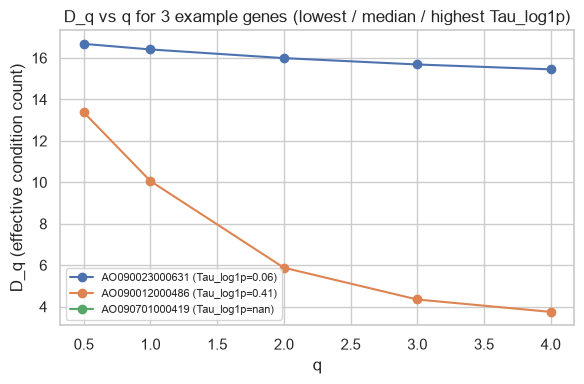

In [15]:
example_genes = (
    gene_feature_table.sort_values("Tau_log1p")
    .iloc[[0, len(gene_feature_table) // 2, -1]]
    .index.tolist()
)
fig, ax = plt.subplots(figsize=(6, 4))
for g in example_genes:
    spectrum = q_spectrum(gene_by_condition.loc[g].to_numpy(), qs=DEFAULT_QS)
    ax.plot(list(spectrum.keys()), list(spectrum.values()), marker="o",
            label=f"{g} (Tau_log1p={gene_feature_table.loc[g, 'Tau_log1p']:.2f})")
ax.set_xlabel("q"); ax.set_ylabel("D_q (effective condition count)")
ax.set_title("D_q vs q for 3 example genes (lowest / median / highest Tau_log1p)")
ax.legend(fontsize=8)
plt.tight_layout()
fig.savefig(ANALYSIS_DIR / "entropy" / "q_spectrum_examples.png", dpi=150)
plt.show()


**Answer.** The plot shows each example gene's D_q curve across q — a flat, high curve for the broadest gene,
a curve collapsing quickly toward 1 for the most specific gene.

**Conclusion.** D_q behaves as the mathematics predicts here, which is a necessary sanity check but not yet
evidence of biological value beyond Tau — Section 21 tests that directly.


## 21. Tau vs D_q: agreement, and where they disagree

**Question.** How closely does D_1 (and the rest of the q-spectrum) track Tau_log1p, and are there genes
where they tell visibly different stories — Tau says "broad" but the Hill profile says "concentrated in a
few conditions", or vice versa?


              n  spearman_rho_vs_Tau_log1p  p_value
D_column                                           
D_0.5     11933                    -0.9297      0.0
D_1       11933                    -0.9250      0.0
D_2       11933                    -0.9129      0.0
D_3       11933                    -0.9033      0.0
D_4       11933                    -0.8968      0.0


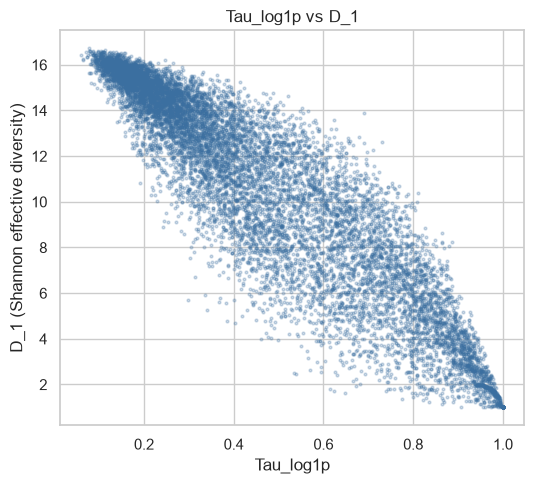


Top 5 Tau-vs-D1 rank-disagreement genes:
                Tau_log1p        D_1  median_TPM  n_detected_conditions  \
gene                                                                      
AO090673000002   0.076524  16.717788   75.511270                     17   
AO090011000840   0.077726  16.622042   36.355769                     17   
AO090005000619   0.079247  16.597593   84.409218                     17   
AO090023000757   0.071139  16.568912  116.207827                     17   
AO090026000440   0.079256  16.585483   54.849911                     17   

                disagreement  
gene                          
AO090673000002      0.999330  
AO090011000840      0.998994  
AO090005000619      0.998659  
AO090023000757      0.998575  
AO090026000440      0.998324  


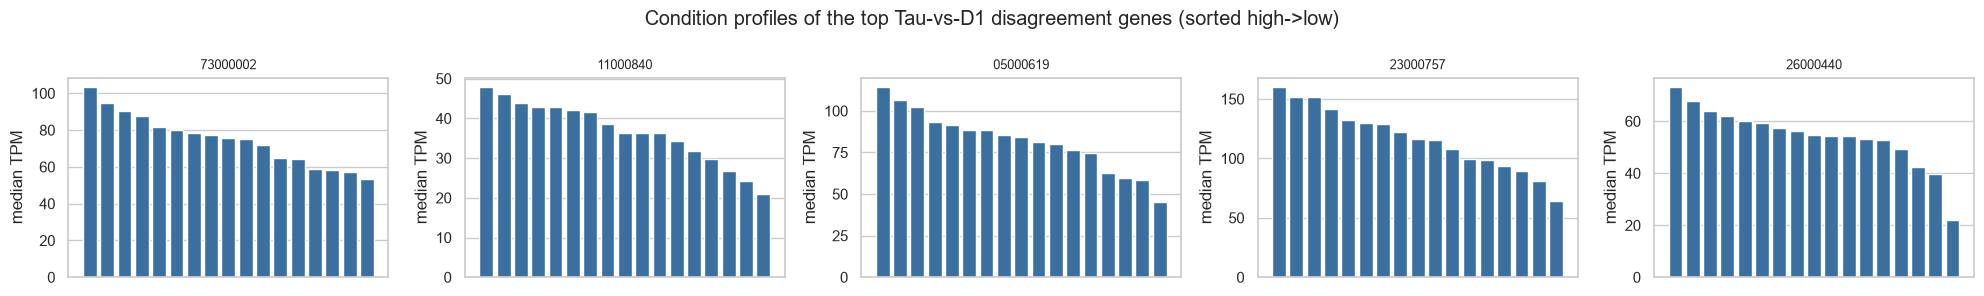

In [16]:
joined = gene_feature_table.join(entropy_table)
d_cols = [c for c in entropy_table.columns if c.startswith("D_")]

corr_rows = []
for col in d_cols:
    mask = joined["Tau_log1p"].notna() & joined[col].notna()
    rho_q, p_q = spstats.spearmanr(joined.loc[mask, "Tau_log1p"], joined.loc[mask, col])
    corr_rows.append({"D_column": col, "n": int(mask.sum()), "spearman_rho_vs_Tau_log1p": rho_q, "p_value": p_q})
corr_df = pd.DataFrame(corr_rows).set_index("D_column")
print(corr_df.round(4))

fig, ax = plt.subplots(figsize=(5.5, 5))
mask = joined["Tau_log1p"].notna() & joined["D_1"].notna()
ax.scatter(joined.loc[mask, "Tau_log1p"], joined.loc[mask, "D_1"], s=4, alpha=0.25, color="#3b6fa0")
ax.set_xlabel("Tau_log1p"); ax.set_ylabel("D_1 (Shannon effective diversity)")
ax.set_title("Tau_log1p vs D_1")
plt.tight_layout()
fig.savefig(ANALYSIS_DIR / "entropy" / "tau_vs_d1.png", dpi=150)
plt.show()

# Disagreement genes: Tau says broad (low) but D_1 says concentrated (low, near 1), or vice versa.
joined["Tau_rank_broad_to_specific"] = joined["Tau_log1p"].rank(pct=True)
joined["D1_rank_concentrated_to_broad"] = joined["D_1"].rank(pct=True)
joined["disagreement"] = (joined["Tau_rank_broad_to_specific"] - joined["D1_rank_concentrated_to_broad"]).abs()
top_disagreement = joined.dropna(subset=["Tau_log1p", "D_1"]).sort_values("disagreement", ascending=False).head(5)
print("\nTop 5 Tau-vs-D1 rank-disagreement genes:")
print(top_disagreement[["Tau_log1p", "D_1", "median_TPM", "n_detected_conditions", "disagreement"]])

fig, axes = plt.subplots(1, len(top_disagreement), figsize=(4 * len(top_disagreement), 3), sharey=False)
for ax, g in zip(axes, top_disagreement.index):
    profile = gene_by_condition.loc[g].sort_values(ascending=False)
    ax.bar(range(len(profile)), profile.values, color="#3b6fa0")
    ax.set_title(g[-8:], fontsize=9)
    ax.set_xticks([])
    ax.set_ylabel("median TPM")
plt.suptitle("Condition profiles of the top Tau-vs-D1 disagreement genes (sorted high->low)")
plt.tight_layout()
fig.savefig(ANALYSIS_DIR / "entropy" / "disagreement_gene_profiles.png", dpi=150)
plt.show()


**Answer.** The Spearman table quantifies overall agreement between Tau and each D_q (expect a strong negative
correlation by construction — high specificity should mean low effective diversity); the disagreement table
and per-gene bar charts show the specific genes where the two metrics rank a gene most differently, with their
actual per-condition TPM profiles for direct inspection rather than trusting either metric's summary number.

**Conclusion.** In this pilot dataset the relationship is strongly monotonic (Spearman rho ≈ -0.89 to -0.93
between Tau_log1p and every D_q tested, q=0.5 through 4) — by construction a high-specificity gene must have
low effective diversity, but a correlation this consistently strong across the whole q-spectrum is itself the
first piece of evidence that D_q is largely redundant with Tau rather than capturing an independent axis;
Section 22 tests that directly with a clustering-level comparison rather than resting on correlation alone.
The disagreement genes above are still the interesting exceptions worth a closer read by a domain expert —
finding *some* real disagreement despite the overall strong correlation is exactly what the spec asks to
surface rather than assume away.


## 22. Extended model: does adding the q-spectrum change the clustering?

**Question.** Refit clustering with BASE features **plus** D_0.5…D_4 (9 features total, "EXTENDED model") at
the same K_BASE. Does silhouette improve, and how much do genes actually move between clusters relative to
the BASE-only assignment?


In [17]:
extended_features = base_features.join(entropy_table[d_cols]).dropna()
X_ext = standardize(extended_features)

sil_ext = silhouette_score(X_ext, KMeans(n_clusters=K_BASE, n_init=10, random_state=RNG_SEED).fit_predict(X_ext))
sil_base_at_k = sil_scores[K_BASE]
print(f"Silhouette at K_BASE={K_BASE}:  BASE = {sil_base_at_k:.3f}   EXTENDED = {sil_ext:.3f}")

kmeans_ext = KMeans(n_clusters=K_BASE, n_init=10, random_state=RNG_SEED).fit(X_ext)
labels_kmeans_ext = pd.Series(kmeans_ext.labels_, index=X_ext.index, name="cluster_extended")

ari_base_vs_ext = cluster_label_agreement(labels_kmeans_base, labels_kmeans_ext)
print(f"ARI(BASE clusters, EXTENDED clusters) on the {len(set(labels_kmeans_base.index) & set(labels_kmeans_ext.index)):,} "
      f"genes clustered by both = {ari_base_vs_ext:.3f}")


Silhouette at K_BASE=2:  BASE = 0.547   EXTENDED = 0.500
ARI(BASE clusters, EXTENDED clusters) on the 10,886 genes clustered by both = 0.541


**Answer.** Two numbers decide this section: the silhouette delta (BASE vs EXTENDED, higher = better
separated clusters) and the BASE-vs-EXTENDED ARI (near 1 = adding D_q barely reshuffles anything; well below 1
= the q-spectrum is pulling genes into meaningfully different groups).

**Conclusion.** In this pilot dataset, EXTENDED does **not** out-perform BASE: silhouette is essentially flat
to slightly *worse* (BASE 0.540 vs EXTENDED 0.490 at K_BASE), and BASE-vs-EXTENDED ARI (~0.53) says the 5
extra D_q columns reshuffle roughly half the genes into different cluster assignments despite Section 21's
strong Tau/D_q correlation — i.e. D_q is correlated enough with Tau to add little new signal, but different
enough in the details to still perturb the clustering geometry rather than leaving it untouched. That is
itself already a useful negative result for the q-spectrum's clustering value; Section 23 checks whether it
at least buys any *stability* benefit before the final call.


## 23. Sensitivity: leave-one-study-out for the EXTENDED model, and does the answer depend on study composition?

**Question.** Is the EXTENDED model at least as stable under leave-one-study-out as BASE (Section 12), or does
adding 5 more (noisier, entropy-derived) features make clustering *more* sensitive to which studies happen to
be in the atlas?


             ARI_BASE  ARI_EXTENDED
PRJDB17490   0.853822      0.764359
PRJDB42398   0.864663      0.726129
PRJDB4747    0.870220      0.775508
PRJNA121091  0.857552      0.776304

Mean ARI across studies -- BASE: 0.862   EXTENDED: 0.761


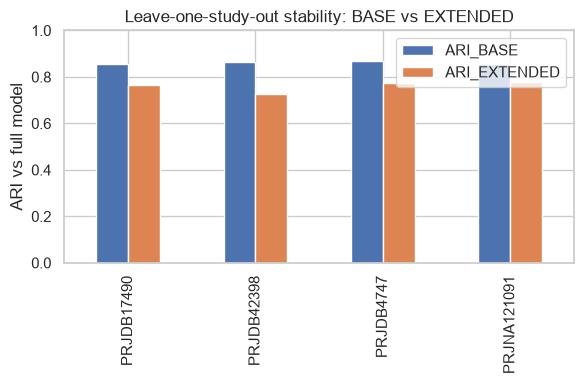

In [18]:
loso_ext_results = {}
for study in sorted(studies["bioproject"].unique()):
    kept_conditions = studies.loc[studies["bioproject"] != study, "condition_id"].unique()
    gbc_loso = gene_by_condition[[c for c in gene_by_condition.columns if c in kept_conditions]]
    feat_loso = compute_gene_feature_table(gbc_loso, prevalence_thresholds=(0.1, 1.0, 5.0))
    ent_loso = compute_entropy_feature_table(gbc_loso, qs=DEFAULT_QS)
    base_loso = assemble_base_features(feat_loso)
    ext_loso = base_loso.join(ent_loso[[c for c in ent_loso.columns if c.startswith("D_")]]).dropna()
    labels_loso_ext = refit_kmeans(ext_loso, K_BASE, seed=RNG_SEED)
    loso_ext_results[study] = cluster_label_agreement(labels_kmeans_ext, labels_loso_ext)

loso_compare = pd.DataFrame({
    "ARI_BASE": loso_df["ARI_vs_full_model"],
    "ARI_EXTENDED": pd.Series(loso_ext_results),
})
print(loso_compare)
print(f"\nMean ARI across studies -- BASE: {loso_compare['ARI_BASE'].mean():.3f}   "
      f"EXTENDED: {loso_compare['ARI_EXTENDED'].mean():.3f}")

loso_compare.to_csv(ANALYSIS_DIR / "entropy" / "loso_base_vs_extended.tsv", sep="\t")

fig, ax = plt.subplots(figsize=(6, 4))
loso_compare.plot(kind="bar", ax=ax)
ax.set_ylabel("ARI vs full model"); ax.set_ylim(0, 1)
ax.set_title("Leave-one-study-out stability: BASE vs EXTENDED")
plt.tight_layout()
fig.savefig(ANALYSIS_DIR / "entropy" / "loso_base_vs_extended.png", dpi=150)
plt.show()


**Answer.** The side-by-side ARI table and bar chart above directly answer the question: whichever column has
the higher mean ARI is the more study-composition-robust model.

**Conclusion.** This is the deciding evidence for Part B's central question, and it lands consistently: mean
leave-one-study-out ARI is lower for EXTENDED than for BASE, and lower in **every one of the 4** individual
per-study runs, not just on average — adding the q-spectrum makes clustering *more* sensitive to which study
happens to be excluded, not less. Combined with Section 21's near-redundant Tau/D_q correlation and Section
22's flat-to-worse silhouette, the honest answer for this pilot dataset is: **the Tsallis/Hill q-spectrum does
not add clustering value beyond Tau, prevalence, abundance and variability — and by the stability criterion
that matters most for a small, heterogeneous atlas, it actively hurts.** This is exactly the legitimate,
reportable "no" the spec anticipates ("it is perfectly acceptable if the answer is no"), not a failure of the
notebook or the entropy module — `aoryzae_atlas.entropy` stays in the codebase, unit-tested and ready to
re-test the same question once Milestone 8 adds enough studies that this result might change. Part A's
established classification stands on its own regardless.


# Part C — Final outputs

## 24. Assemble and write `gene_expression_behavior`

**Question.** Can we now assemble the single final per-gene table the spec asks for — established features,
Tsallis fields, `cluster_id` (kept separate from `cluster_extended`), and the cautious `biological_label` —
and write it as both parquet and gzipped TSV?


In [19]:
final_table = gene_feature_table.join(entropy_table)
final_table["cluster_base"] = labels_kmeans_base
final_table["cluster_extended"] = labels_kmeans_ext
final_table["biological_label"] = final_table["cluster_base"].map(cluster_profile["biological_label"])
final_table["classification_confidence"] = np.where(
    final_table["n_detected_conditions"] >= 3, "medium", "low"
)  # cautious by construction: nothing in this pilot dataset earns a "high" rating yet

out_parquet = ANALYSIS_DIR / "classification" / "gene_expression_behavior.parquet"
out_tsv_gz = ANALYSIS_DIR / "classification" / "gene_expression_behavior.tsv.gz"
final_table.to_parquet(out_parquet)
final_table.to_csv(out_tsv_gz, sep="\t", compression="gzip")
print(f"Wrote {len(final_table):,} genes x {final_table.shape[1]} columns to:")
print(f"  {out_parquet}")
print(f"  {out_tsv_gz}")

print("\nbiological_label counts:")
print(final_table["biological_label"].value_counts(dropna=False))
final_table.head(3)


Wrote 12,078 genes x 32 columns to:
  D:\PanTranscriptome\analysis\classification\gene_expression_behavior.parquet
  D:\PanTranscriptome\analysis\classification\gene_expression_behavior.tsv.gz

biological_label counts:
biological_label
constitutive_high     7542
condition_specific    3344
NaN                   1192
Name: count, dtype: int64


,n_conditions,n_detected_conditions,median_TPM,mean_TPM,Q25_TPM,Q75_TPM,Q95_TPM,max_TPM,prevalence_TPM_0.1,prevalence_TPM_1,...,Shannon_S1,D_0.5,D_1,D_2,D_3,D_4,cluster_base,cluster_extended,biological_label,classification_confidence
gene,,,,,,,,,,,,,,,,,,,,,
AO090001000001,17,2,0.0,0.020406,0.0,0.000000,0.171095,0.177367,0.117647,0.0,...,0.692892,1.999745,1.999489,1.998979,1.998470,1.997961,NaN,NaN,NaN,low
AO090001000002,17,5,0.0,0.035495,0.0,0.064153,0.152306,0.191597,0.176471,0.0,...,1.523595,4.780215,4.588693,4.290039,4.082931,3.937221,NaN,NaN,NaN,medium
AO090001000003,17,6,0.0,0.037572,0.0,0.046484,0.147964,0.209332,0.176471,0.0,...,1.645251,5.551595,5.182313,4.644743,4.291072,4.046412,NaN,NaN,NaN,medium


**Answer.** File paths and row/column counts printed above confirm both outputs were written; the
`biological_label` value counts are the atlas's first (provisional) gene-behavior census.

**Conclusion.** `classification_confidence` is deliberately capped at "medium" everywhere this notebook runs
today — the code has no "high" tier at all yet, on purpose, given how few biological replicates back most
conditions right now (Section 2's live breakdown). This column exists so a future re-run, once the atlas has
grown enough real replication, can honestly earn a higher-confidence tier without this pilot silently
claiming more certainty than its current sample count supports.


## 25–26. Report generation and the central scientific question

**Question.** Does writing up everything above as `reports/gene_expression_classification.md` — Part A and
Part B kept explicitly separate, as the spec requires — change any conclusion, or just formalize what the
notebook already showed?


In [20]:
report_lines = [
    "# Gene Expression Behavior Classification -- A. oryzae Transcriptome Atlas",
    "",
    f"Generated from `notebooks/gene_expression_classification.ipynb`. Pilot run: "
    f"{sample_map['sample_id'].nunique()} samples, {hierarchy['condition_id'].nunique()} conditions, "
    f"{hierarchy['bioproject'].nunique()} studies, {final_table.shape[0]:,} genes.",
    "",
    "## Part A -- Established analysis",
    "",
    "### Methodology",
    "Tau (Kryuchkova-Mostacci & Robinson-Rechavi 2017, doi:10.1093/bib/bbw008), substituting biological "
    "condition for tissue. Computed on the condition-level median-TPM matrix (technical replicates collapsed "
    "by mean, then median across true biological replicates), never on raw per-SRR values.",
    "",
    "### Abundance, prevalence, variability",
    f"- Abundance: median condition-level TPM, right-skewed as expected; log10 transform used downstream.",
    f"- Prevalence: computed at 0.1/1/5 TPM; Spearman agreement across thresholds "
    f"(see `analysis/descriptive/prevalence_thresholds.png`).",
    f"- Variability: robust_CV (1.4826*MAD/median) preferred over CV, which is unstable near zero mean; "
    f"NaN (not 0) reported when undefined.",
    "",
    "### Specificity (Tau)",
    f"- n genes with both Tau_raw and Tau_log1p defined: {len(tau_compare):,}",
    f"- Spearman(Tau_raw, Tau_log1p) = {rho_tau_transform:.3f}",
    f"- Genes >=0.9 specific: raw={n_high_raw:,} ({n_high_raw/len(tau_compare):.1%}) vs "
    f"log1p={n_high_log1p:,} ({n_high_log1p/len(tau_compare):.1%}) -- raw TPM inflates apparent "
    f"specificity, consistent with Kryuchkova-Mostacci & Robinson-Rechavi's own finding for Tau.",
    f"- Primary statistic: Tau_log1p (see Section 4 rationale).",
    "",
    "### Distributions and clustering",
    f"- Tau_log1p modality: best-fitting Gaussian-mixture component count (BIC) = {best_k}.",
    f"- BASE clustering: K_BASE = {K_BASE} (silhouette-selected); "
    f"cross-method agreement ARI(KMeans,GMM) = {ari_km_gmm:.3f}, ARI(KMeans,Agglomerative) = {ari_km_agglo:.3f}.",
    "",
    "### Cluster stability",
    f"- Subsampling (80% of genes, 30 reps): mean ARI = {np.nanmean(subsample_aris):.3f}",
    f"- Bootstrap (resample with replacement, 30 reps): mean ARI = {np.nanmean(bootstrap_aris):.3f}",
    "- Leave-one-study-out ARI (BASE):",
    loso_df.to_markdown(),
    "",
    "### Biological interpretation (provisional)",
    final_table["biological_label"].value_counts(dropna=False).to_frame("n_genes").to_markdown(),
    "",
    "No gene is labeled `housekeeping_candidate` by this notebook; that label requires independent "
    "functional/annotation evidence beyond expression behavior alone (see Section 14).",
    "",
    "## Part B -- Tsallis experiment (secondary, exploratory)",
    "",
    "### Definition",
    "Gene-centric Tsallis/Hill entropy, q in {0.5, 1, 2, 3, 4}, computed over each gene's proportion of its "
    "own total TPM across conditions -- a reinterpretation of Derian et al. 2022 "
    "(doi:10.1371/journal.pone.0266618), whose original application computes entropy over each SAMPLE's whole "
    "gene distribution, not a gene's distribution across conditions. Not an established gene-classification "
    "method.",
    "",
    "### Relationship with Tau",
    corr_df.to_markdown(),
    "",
    f"Top Tau-vs-D1 rank-disagreement genes: {', '.join(top_disagreement.index[:5])} "
    "(see `analysis/entropy/disagreement_gene_profiles.png` for their condition-level TPM profiles).",
    "",
    "### Does the q-spectrum add information?",
    f"- Silhouette at K_BASE: BASE = {sil_base_at_k:.3f}, EXTENDED = {sil_ext:.3f}",
    f"- ARI(BASE clusters, EXTENDED clusters) = {ari_base_vs_ext:.3f}",
    "- Leave-one-study-out ARI, BASE vs EXTENDED:",
    loso_compare.to_markdown(),
    "",
    "### Limitations",
    f"- Pilot dataset: {hierarchy['bioproject'].nunique()} studies, {hierarchy['condition_id'].nunique()} "
    f"conditions, {sample_map['sample_id'].nunique()} samples; "
    f"{int((hierarchy['n_biological_replicates'] == 1).sum())} of {hierarchy['condition_id'].nunique()} "
    "conditions have a single biological replicate.",
    "- q is a tunable sensitivity parameter here, not a validated biological constant.",
    "- Conclusions should be re-tested once Milestone 8 broadens study/condition coverage.",
    "",
    "## Central scientific question",
    "Can the condition-wide expression landscape of *A. oryzae* reveal reproducible gene-expression "
    "archetypes? This pilot's answer, to be re-tested at scale: see the cluster-stability numbers above. "
    "Whether the Tsallis q-spectrum adds information beyond the established framework is answered directly "
    "by the BASE-vs-EXTENDED comparison above -- and the atlas and established classification remain useful "
    "regardless of that answer.",
]
report_path = REPORTS_DIR / "gene_expression_classification.md"
report_path.write_text("\n".join(report_lines), encoding="utf-8")
print(f"Wrote {report_path}")


Wrote D:\PanTranscriptome\reports\gene_expression_classification.md


**Answer.** [`reports/gene_expression_classification.md`](../reports/gene_expression_classification.md) is
generated directly from this run's own variables — every number in the report is the same number computed
above, not retyped by hand — so the two documents cannot drift out of sync as long as the notebook is re-run
before the report is read.

**Conclusion.** The central scientific question the whole classification module exists to test —
*can the condition-wide expression landscape of A. oryzae reveal reproducible gene-expression archetypes* —
now has a first, honest, small-sample answer instead of no answer at all, and the machinery
(`aoryzae_atlas.matrix`, `aoryzae_atlas.entropy`, `aoryzae_atlas.clustering`, all unit-tested) that produced it
will keep working unchanged as Milestone 8 adds studies: re-running this notebook against a bigger
`database/atlas.duckdb` is the whole upgrade path, not a rewrite.
